In [1]:
import random
import numpy as np

In [2]:
%timeit [random.random() for _ in range(100_000)]

45.5 ms ± 2 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [3]:
%timeit np.random.rand(100_000)

The slowest run took 7.15 times longer than the fastest. This could mean that an intermediate result is being cached.
2.76 ms ± 3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame({
    "model": ["Linear", "Random Forest", "Neural Net"],
    "accuracy": [0.72, 0.89, 0.94],
}).to_csv("results.csv", index=False)

In [5]:
df = pd.read_csv("results.csv")
df

,model,accuracy
0,Linear,0.72
1,Random Forest,0.89
2,Neural Net,0.94


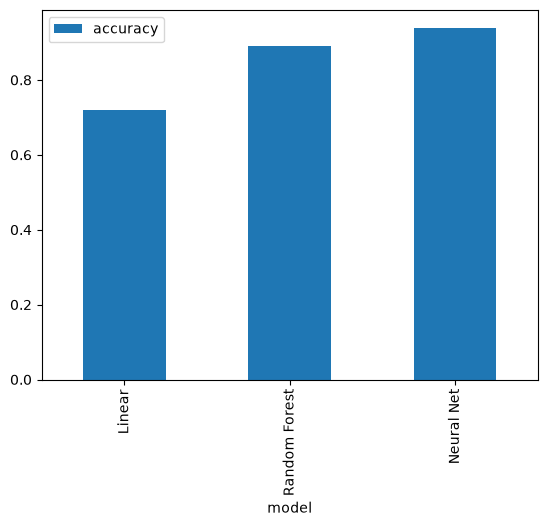

In [6]:
df.plot(x="model", y="accuracy", kind="bar")
plt.show()

In [1]:
cat phases/00-setup-and-tooling/05-jupyter-notebooks/code/notebook_tips.py

import time
import sys

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd


def timing_comparison():
    print("=== Timing: List vs NumPy ===\n")

    size = 1_000_000

    start = time.perf_counter()
    python_list = [x ** 2 for x in range(size)]
    list_time = time.perf_counter() - start
    print(f"List comprehension: {list_time:.4f}s")

    start = time.perf_counter()
    numpy_array = np.arange(size) ** 2
    numpy_time = time.perf_counter() - start
    print(f"NumPy:              {numpy_time:.4f}s")
    print(f"Speedup:            {list_time / numpy_time:.1f}x")


def inline_plotting():
    print("\n=== Inline Plotting ===\n")

    np.random.seed(42)
    x = np.linspace(0, 10, 200)
    y_sin = np.sin(x)
    y_noisy = y_sin + np.random.normal(0, 0.2, 200)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(x, y_sin, label="sin(x)")
    axes[0].plot(x, y_noisy, alpha=0.5, label="noisy")
    axes[0].se